# 05 - Where RL Fits in the Autonomy Stack

## Imports

In [1]:
import copy
import heapq
import warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

# Make sure we get outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)

## The Big Question: Where Does This Go? 

`01` through `04` taught how to train a policy from reward. Meanwhile `perception_primer/08`-`10` and `frc_resources/09` built a driving stack out of classical parts: a global planner, a path tracker, a reactive layer, a supervisor. Where do we use these tools? 

The honest answer is it depends on which layer, and it depends on specific things you can check. Here is a rough sort of that stack:

| Layer | Learned policy a good fit? | Why |
|---|---|---|
| Localization | Not as an RL policy | There's a model (odometry plus tag measurements) and estimation theory built for it. It isn't a decision problem. |
| Perception / tracking | Supervised learning, not RL | Labeled data exists. That's `cv_primer` and `perception_primer`. |
| Global planner | Rarely | If you have a map and a cost, A\* gives the optimal answer with no training. It adapts the moment the map changes. |
| Path tracker | Rarely | A well-tuned controller on a known drivetrain is hard to beat, and needs no training episodes. |
| Reactive layer | Sometimes | Useful when the interaction is too messy to hand-write. Hard to certify. |
| Supervisor | No | This layer exists to be predictable. |
| Strategy (what to do, what to pick) | **Yes** | No map, no model, a reward you can write down, and a decision that repeats. This is `01`-`04`'s draft. |

That table isn't a law, so this notebook tests the one row people argue about most: could a learned policy replace the planner and tracker? We'll set up a small case where the answer is interesting.

## A World Where the Planner's Model Is Wrong

The robot starts in the bottom-left corner and needs to reach the bottom-right. Between them runs the edge of a field element, shown in red. Touching it ends the run. A\* will plan along the shortest route that doesn't touch it.

The catch is that the planner assumes the drivetrain does what it's told, but ours doesn't. 15% of the time the robot does something random instead (wheel slip, a bump, a latency spike). We don't give that fact to the planner, which is the usual situation when the model quietly leaves something out that we never noticed. It does give us a chance to compare a planner with a learned policy that gets to see what actually happens.

In [2]:
H, W = 7, 12
START, GOAL = (6, 0), (6, 11)
CLIFF = {(6, c) for c in range(1, 11)}          # the edge of a field element: touching it ends the run
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]      # up, down, left, right
SLIP = 0.15                                     # chance the drivetrain does something random instead
MAX_STEPS = 60

def step_env(cell, action, blocked, rng):
    """ One real-world step. Returns (next_cell, reward, outcome) with outcome in {None, 'goal', 'crash'}. """
    if rng.random() < SLIP:
        action = rng.integers(4)
    r, c = cell[0] + MOVES[action][0], cell[1] + MOVES[action][1]
    nxt = (r, c) if 0 <= r < H and 0 <= c < W and (r, c) not in blocked else cell
    if nxt in CLIFF:
        return nxt, -100.0, 'crash'
    if nxt == GOAL:
        return nxt, -1.0, 'goal'
    return nxt, -1.0, None

def a_star(blocked, margin=0, start=START, goal=GOAL):
    """ A* on the planner's model: no slip. `margin` treats cells within that many cells of the cliff as blocked. """
    def keep_out(cell):
        near_cliff = any(abs(cell[0] - cr) + abs(cell[1] - cc) <= margin for cr, cc in CLIFF) if margin else False
        return cell in CLIFF or cell in blocked or (near_cliff and cell not in (start, goal))
    openset = [(0.0, 0.0, start)]
    came, best = {}, {start: 0.0}
    while openset:
        _, g, cur = heapq.heappop(openset)
        if cur == goal:
            path = [cur]
            while path[-1] in came:
                path.append(came[path[-1]])
            return path[::-1]
        for dr, dc in MOVES:
            n = (cur[0] + dr, cur[1] + dc)
            if 0 <= n[0] < H and 0 <= n[1] < W and not keep_out(n) and g + 1 < best.get(n, 1e9):
                best[n] = g + 1
                came[n] = cur
                heapq.heappush(openset, (g + 1 + abs(n[0] - goal[0]) + abs(n[1] - goal[1]), g + 1, n))
    return None

def plan_action(cell, blocked, margin=0):
    path = a_star(blocked, margin, start=cell)
    if path is None or len(path) < 2:
        return None
    return MOVES.index((path[1][0] - cell[0], path[1][1] - cell[1]))

def run_episode(choose_action, blocked, rng):
    getattr(choose_action, 'reset', lambda: None)()      # a stateful controller (like the supervisor below) starts fresh
    cell = START
    for _ in range(MAX_STEPS):
        a = choose_action(cell)
        if a is None:
            return 'stuck'
        cell, _, outcome = step_env(cell, a, blocked, rng)
        if outcome:
            return outcome
    return 'timeout'

def evaluate(choose_action, blocked, n=500, seed=0):
    rng = np.random.default_rng(seed)
    results = [run_episode(choose_action, blocked, rng) for _ in range(n)]
    return {k: results.count(k) / n for k in ['goal', 'crash', 'timeout', 'stuck']}

class QAgent:
    def __init__(self):
        self.Q = np.zeros((H, W, 4))
        self.episodes = 0

    def act(self, cell):
        return int(self.Q[cell].argmax())

    def train(self, n_episodes, blocked, rng, alpha=0.1, gamma=0.99, epsilon=0.1):
        for _ in range(n_episodes):
            cell = START
            for _ in range(MAX_STEPS):
                a = rng.integers(4) if rng.random() < epsilon else int(self.Q[cell].argmax())
                nxt, reward, outcome = step_env(cell, a, blocked, rng)
                target = reward if outcome else reward + gamma * self.Q[nxt].max()
                self.Q[cell][a] += alpha * (target - self.Q[cell][a])
                cell = nxt
                if outcome:
                    break
            self.episodes += 1

def greedy_path(agent, blocked, limit=40):
    """ Where a trained agent drives if nothing slips. """
    cell, path = START, [START]
    for _ in range(limit):
        dr, dc = MOVES[agent.act(cell)]
        nxt = (cell[0] + dr, cell[1] + dc)
        if not (0 <= nxt[0] < H and 0 <= nxt[1] < W) or nxt in blocked:
            break
        cell = nxt
        path.append(cell)
        if cell == GOAL or cell in CLIFF:
            break
    return path

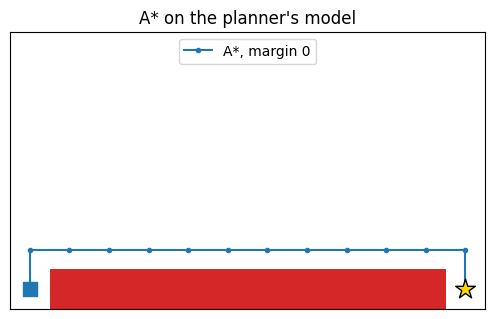

In [3]:
def draw(ax, blocked, paths=(), title=""):
    img = np.zeros((H, W))
    for r, c in CLIFF:
        img[r, c] = 1
    for r, c in blocked:
        img[r, c] = 2
    ax.imshow(img, cmap=matplotlib_cmap, vmin=0, vmax=2)
    for path, color, label in paths:
        ax.plot([c for r, c in path], [r for r, c in path], "-o", color=color, markersize=3, label=label)
    ax.scatter([START[1]], [START[0]], marker="s", s=90, color="tab:blue", zorder=5)
    ax.scatter([GOAL[1]], [GOAL[0]], marker="*", s=220, color="gold", edgecolor="black", zorder=5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

from matplotlib.colors import ListedColormap
matplotlib_cmap = ListedColormap(["white", "tab:red", "dimgray"])

no_block = set()
fig, ax = plt.subplots(figsize=(8, 3.6))
draw(ax, no_block, [(a_star(no_block), "tab:blue", "A*, margin 0")], "A* on the planner's model")
ax.legend(loc="upper center")
plt.show()

A\* takes the shortest legal route, which runs along the row right above the red cells. On the planner's model that is the best possible path. On the real robot, one random step in the wrong direction while it's next to the red edge ends the run.

## The Planner, as Written, and With One Fix

We'll run each controller 500 times in the real world, with the slip on. First, A\* as written (`margin=0`). Then A\* with a margin of 1, which is the standard classical fix: treat every cell next to the hazard as blocked too, the same as `perception_primer/09`'s inflated safety margin. That fix needs no training, only someone who knows to ask for it.

A*, margin 0                       reach goal 66.8%   crash 33.2%   time out  0.0%


A*, margin 1                       reach goal 94.2%   crash  5.8%   time out  0.0%


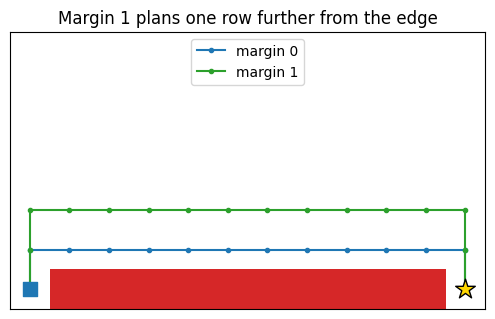

In [4]:
def summarize(name, stats):
    print(f"{name:34s} reach goal {stats['goal']:5.1%}   crash {stats['crash']:5.1%}   time out {stats['timeout']:5.1%}")

astar_results = {}
for margin in [0, 1]:
    astar_results[margin] = evaluate(lambda c, m=margin: plan_action(c, no_block, m), no_block)
    summarize(f"A*, margin {margin}", astar_results[margin])

fig, ax = plt.subplots(figsize=(8, 3.6))
draw(ax, no_block, [(a_star(no_block, 0), "tab:blue", "margin 0"), (a_star(no_block, 1), "tab:green", "margin 1")], "Margin 1 plans one row further from the edge")
ax.legend(loc="upper center")
plt.show()

Margin 0 reaches the goal 67% of the time and crashes in a third of runs. That is almost entirely slip pushing the robot into the red edge while it hugs it. Margin 1 uses the same A\*, with no training, and reaches the goal 94% of the time, because it gives the slip some room. On the planner's own model both routes are fine, and the margin-0 route is the shorter one. The difference only shows up when you run it in the real world.

## Learning It Instead

Now give the same task to the tabular Q-learning agent from `01`. It is never told about the slip, or even about the grid's geometry. It sees which cell it is in, picks a move, and gets back a reward (-1 per step, -100 for touching the red edge). Whatever the slip does to it is in the data, so if a cautious path is better in this world than the shortest one, the agent has what it needs to find that out.

The cost shows up in the x-axis. Every one of these episodes is a real run, and the early ones mostly crash or wander. We'll train 5 agents from scratch and check each one's greedy policy at increasing numbers of episodes.

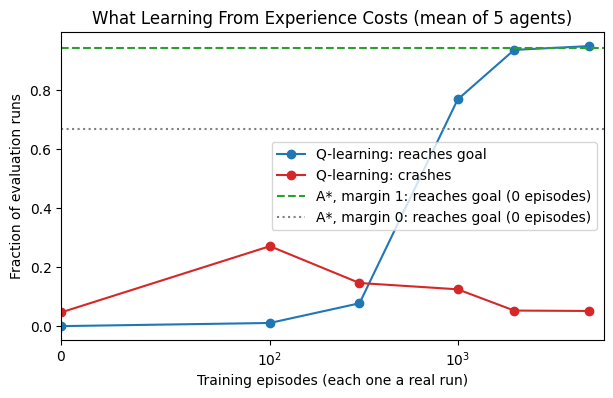

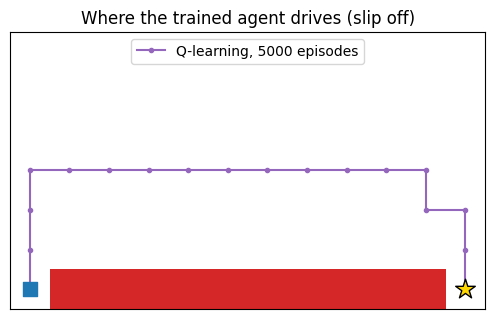

In [5]:
checkpoints = [0, 100, 300, 1000, 2000, 5000]
curve = {"goal": [], "crash": []}
agents = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    agent, done = QAgent(), 0
    goals, crashes = [], []
    for ck in checkpoints:
        agent.train(ck - done, no_block, rng)
        done = ck
        e = evaluate(agent.act, no_block, n=300, seed=seed)
        goals.append(e["goal"])
        crashes.append(e["crash"])
    curve["goal"].append(goals)
    curve["crash"].append(crashes)
    agents.append(agent)

plt.figure(figsize=(7, 4))
plt.plot(checkpoints, np.mean(curve["goal"], axis=0), "o-", label="Q-learning: reaches goal")
plt.plot(checkpoints, np.mean(curve["crash"], axis=0), "o-", color="tab:red", label="Q-learning: crashes")
plt.axhline(astar_results[1]["goal"], color="tab:green", linestyle="--", label="A*, margin 1: reaches goal (0 episodes)")
plt.axhline(astar_results[0]["goal"], color="gray", linestyle=":", label="A*, margin 0: reaches goal (0 episodes)")
plt.xscale("symlog", linthresh=100)
plt.xlim(0, 6000)
plt.xlabel("Training episodes (each one a real run)")
plt.ylabel("Fraction of evaluation runs")
plt.title("What Learning From Experience Costs (mean of 5 agents)")
plt.legend(loc="center right")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
draw(ax, no_block, [(greedy_path(agents[0], no_block), "tab:purple", "Q-learning, 5000 episodes")], "Where the trained agent drives (slip off)")
ax.legend(loc="upper center")
plt.show()

Early on it's bad. After 100 episodes it reaches the goal in about 1% of runs and crashes in about a quarter of them. By 1,000 episodes it's at about 77%, and by 2,000 to 5,000 it reaches the goal in about 94-95% of runs, the same as A\* with margin 1.

Two things to take from that. First, learning found the cautious route on its own. The path in the second picture runs several rows above the edge, and nobody told the agent about slip or about margins. Second, the price is the x-axis. It took on the order of a thousand real runs, and many of the early ones were crashes. On a real robot that isn't a plan, it's a simulator project.

Also notice where it ended up. It went exactly where a one-line classical fix got to with no training. RL didn't beat the planner here. It matched it, without needing to be told what was wrong. That is worth a lot when you don't know what's wrong, and a lot of cost when you do.

## The World Changes

Now suppose another robot parks in the lane, two cells tall, somewhere neither controller has seen. That is one of the most ordinary events in a match. We'll compare a few different ways of dealing with that: 

1. The Q-learning agent as trained, with its table unchanged.
2. A\* with margin 1, which replans on the new map as soon as it sees it.
3. The Q-learning agent retrained for 100 more episodes on the new map.

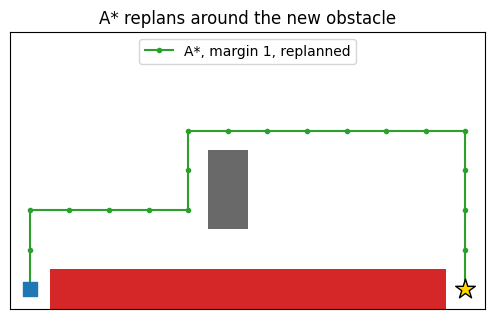

Q-learning, table unchanged        reach goal 65.6%   crash  7.1%   time out 27.3%
A*, margin 1 (replans)             reach goal 94.4%   crash  5.4%   time out  0.0%
Q-learning, +100 episodes          reach goal 94.5%   crash  5.1%   time out  0.4%


In [6]:
new_block = {(3, 5), (4, 5)}      # a parked robot, two cells tall, in the middle lane

fig, ax = plt.subplots(figsize=(8, 3.6))
draw(ax, new_block, [(a_star(new_block, 1), "tab:green", "A*, margin 1, replanned")], "A* replans around the new obstacle")
ax.legend(loc="upper center")
plt.show()

stale = [evaluate(a.act, new_block, n=300, seed=i) for i, a in enumerate(agents)]
replan = evaluate(lambda c: plan_action(c, new_block, 1), new_block)

retrained = []
for i, a in enumerate(agents):
    a2 = copy.deepcopy(a)
    a2.train(100, new_block, np.random.default_rng(100 + i))
    retrained.append(evaluate(a2.act, new_block, n=300, seed=i))

mean_of = lambda runs: {k: float(np.mean([r[k] for r in runs])) for k in runs[0]}
summarize("Q-learning, table unchanged", mean_of(stale))
summarize("A*, margin 1 (replans)", replan)
summarize("Q-learning, +100 episodes", mean_of(retrained))

The stale agent keeps driving the lane it learned. Its moves into the parked robot just bounce it back to where it was, so about a quarter of its runs end in a timeout, and its goal rate falls from about 95% to about 66%. It doesn't fall to zero, because slip sometimes nudges it around the block by accident. A\* replans on the new map and stays at 94%, with no training at all. Retraining the agent for 100 more episodes gets it back to about 95%.

That's a small change on a tiny map, and 100 episodes is cheap here. But every one of them is a real run on the changed field, and a real match doesn't give you 100 tries.

## A Learned Policy Inside, a Classical Layer Around It

There is a better question than "learned or classical". `perception_primer/10` had a supervisor for exactly the case where the plan stops being trustworthy, and it doesn't care where the plan came from. So we can keep the learned policy for what it's good at, and put a classical layer around it.

The supervisor below is a few lines. Each step it asks the learned policy for a move. If that move would hit something we know about (a blocked cell, the red edge, or a wall), or if the robot has been in the same cell more than 3 times (stuck in a loop), it ignores the learned policy and takes A\*'s next step instead.

In [7]:
class Supervised:
    """ A learned policy with a classical supervisor around it (compare perception_primer/10's supervisor). """
    def __init__(self, agent, blocked, margin=1, max_visits=3):
        self.agent, self.blocked, self.margin, self.max_visits = agent, blocked, margin, max_visits
        self.reset()

    def reset(self):
        self.visits = {}

    def __call__(self, cell):
        self.visits[cell] = self.visits.get(cell, 0) + 1
        action = self.agent.act(cell)
        r, c = cell[0] + MOVES[action][0], cell[1] + MOVES[action][1]
        bad_move = not (0 <= r < H and 0 <= c < W) or (r, c) in self.blocked or (r, c) in CLIFF
        if bad_move or self.visits[cell] > self.max_visits:
            return plan_action(cell, self.blocked, self.margin)
        return action

rows = {}
for world_name, blocked in [("original world", no_block), ("with parked robot", new_block)]:
    rows[world_name] = {
        "A*, margin 0":               evaluate(lambda c: plan_action(c, blocked, 0), blocked),
        "A*, margin 1":               evaluate(lambda c: plan_action(c, blocked, 1), blocked),
        "Q-learning alone":           mean_of([evaluate(a.act, blocked, n=300, seed=i) for i, a in enumerate(agents)]),
        "Q-learning + supervisor":    mean_of([evaluate(Supervised(a, blocked), blocked, n=300, seed=i) for i, a in enumerate(agents)]),
    }

print(f"{'':28s}" + "".join(f"{w:>34s}" for w in rows))
print(f"{'':28s}" + "".join(f"{'reach goal':>17s}{'crash':>17s}" for _ in rows))
for name in rows["original world"]:
    line = f"{name:28s}"
    for w in rows:
        line += f"{rows[w][name]['goal']:17.1%}{rows[w][name]['crash']:17.1%}"
    print(line)

                                                original world                 with parked robot
                                   reach goal            crash       reach goal            crash
A*, margin 0                            66.8%            33.2%            63.0%            37.0%
A*, margin 1                            94.2%             5.8%            94.4%             5.4%
Q-learning alone                        94.8%             5.1%            65.6%             7.1%
Q-learning + supervisor                 94.3%             5.7%            95.3%             4.7%


In the original world the supervisor almost never has to step in, so wrapping the learned policy costs nothing (94.3% against 94.8%). In the changed world the wrapped policy reaches the goal 95% of the time, which matches A\* with margin 1, and it did so with no retraining. Where the learned policy proposes a move into the parked robot, the supervisor catches it and substitutes a planned step, and the learned policy takes over again once the way is clear.

Be clear about who is doing the work there. In the changed world, much of it is the classical layer, and that is the design working as intended. The learned policy contributes where its experience helps (the cautious route), and the classical layer handles what the learned policy has never seen. Try It Yourself #2 pushes on how far that goes.

## What This Means for Our Robot

The pattern this toy shows holds up in real systems, and it lines up with `frc_resources/09`'s map from the simulator's layers to FRC tools.

Use the classical tool when you have a model and it's mostly right. PathPlanner, a pose estimator, and a well-tuned drive controller already encode what we know about driving, and they cost zero training episodes. When the model is slightly wrong in a way you can name, a classical fix (a margin, a velocity limit, a tuned gain) usually gets you most of the way. The inflated margin matched the learned agent here with no training at all.

Reach for RL when the model is missing or wrong in a way you can't name, the world is stable, and you can afford the trials. The agent found the cautious route without anyone telling it the slip rate. The price was around a thousand real runs, each of them a crash early on. On a robot that is a sim-to-real project: you train in a simulator, and the simulator's slip rate becomes the thing you have to get right. A policy trained against a wrong simulator will be confidently wrong on the real drivetrain, which is `03`'s distribution shift in a different setting.

A learned policy inherits its training world. The change in the lane cost the agent half its success until it relearned. A planner adapted for free. Real matches change constantly, which is why the classical layers stay in the loop.

When you do use a learned policy in the loop, give it a supervisor that is predictable by construction. The supervisor is also what makes a learned policy something you could reasonably let near a real drivetrain, since its worst-case behavior stops being "whatever the network does".

The place RL has already earned its keep for us is further up the stack. Alliance strategy and pick recommendation (`01`-`04`) have no map, no dynamics model, and a reward we can write down, and a bad recommendation costs a conversation instead of a crash, especially with the human approval gate from `ai_resources/agent_primer/10-human-in-the-loop-design.md`.

## Try It Yourself

1. Change `SLIP` from `0.15` to `0.0` and then to `0.4` (re-run from the top). At which slip rate does A\* with margin 0 stop being a reasonable choice, and what happens to the gap between it and Q-learning at each end?
2. Make the world change harder. Block three cells in a column (`new_block = {(2, 5), (3, 5), (4, 5)}`) and compare the four options again. Does the supervisor still keep the learned policy useful, or does it end up doing all the work?
3. Wrap the supervisor around the learned policy but set `max_visits=1`. What happens to the success rate, and what is the supervisor trading away?

In [8]:
# TODO: 1. change SLIP and re-run the comparison

# TODO: 2. block three cells in a column and compare the four options

# TODO: 3. try Supervised(agent, blocked, max_visits=1) against max_visits=3

## Resources

- [PathPlannerLib: Pathfinding](https://pathplanner.dev/pplib-pathfinding.html) - the planner `frc_resources/09` maps the A\* layer onto, including how dynamic obstacles feed it (documentation).
- [Sutton & Barto: *Reinforcement Learning: An Introduction*](http://incompleteideas.net/book/the-book.html) - Example 6.6 (Cliff Walking) is the textbook version of the world used here (textbook).
- Tobin et al. (2017). ["Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World."](https://arxiv.org/abs/1703.06907) One widely used answer to the sim-to-real gap described above (paper).
- `perception_primer/10-full-autonomy-stack.ipynb` - the supervisor this notebook's wrapper is modeled on, inside a full simulated stack.